In [2]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("enterprise_database (1).db")

print("Database connected successfully!")

Database connected successfully!


In [4]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current folder:
C:\Users\Manasa A

Files in this folder:
['.anaconda', '.conda', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.ms-ad', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'enterprise_database (1).db', 'Favorites', 'Links', 'Local Settings', 'Microsoft', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{ef8cb230-7973-11f0-b65f-289200446ca3}.TM.blf', 'NTUSER.DAT{ef8cb230-7973-11f0-b65f-289200446ca3}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{ef8cb230-7973-11f0-b65f-289200446ca3}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Pictures', 'PrintHood', 'Recent', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'Templates', 'Untitled.ipynb', 'Untitled1.ipynb', 'Untitled2.ipynb', 'Untitled3.ipynb', 'Untitled4.ipynb']


In [5]:
# Check the tables available in the database

tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

tables

,name


In [6]:
import os

# Check database file size
db_path = "enterprise_database (1).db"

print("Database file size:", os.path.getsize(db_path), "bytes")

# Reconnect to the database
conn.close()
conn = sqlite3.connect(db_path)

# Check tables again
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print("\nTables found:")
print(tables)

Database file size: 0 bytes

Tables found:
Empty DataFrame
Columns: [name]
Index: []


In [7]:
import os

downloads_path = os.path.join(
    os.path.expanduser("~"),
    "Downloads",
    "enterprise_database (1).db"
)

print("File exists:", os.path.exists(downloads_path))

if os.path.exists(downloads_path):
    print("File size:", os.path.getsize(downloads_path), "bytes")

File exists: True
File size: 2670592 bytes


In [8]:
# Connect to the actual project database in Downloads

conn.close()

conn = sqlite3.connect(downloads_path)

print("Connected to the actual project database!")

# Check available tables
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print("\nTables found:")
print(tables)

Connected to the actual project database!

Tables found:
    name
0  users


In [12]:
# Get the latest record for each user

query = """
SELECT
    user_id,
    name,
    status,
    updated_at
FROM (
    SELECT
        user_id,
        name,
        status,
        updated_at,
        ROW_NUMBER() OVER (
            PARTITION BY user_id
            ORDER BY datetime(updated_at) DESC
        ) AS rn
    FROM users
)
WHERE rn = 1;
"""

latest_users = pd.read_sql_query(query, conn)

print("Latest record extracted for each user!")
print("Number of unique users:", len(latest_users))

latest_users.head()


Latest record extracted for each user!
Number of unique users: 25000


,user_id,name,status,updated_at
0,U-00000,User_U-00000,Suspended,2023-02-28 09:00:00
1,U-00001,User_U-00001,Active,2023-01-28 14:00:00
2,U-00002,User_U-00002,Suspended,2023-02-23 09:00:00
3,U-00003,User_U-00003,Active,2023-01-22 14:00:00
4,U-00004,User_U-00004,Pending,2023-01-01 10:00:00


In [13]:
# Keep only users whose latest status is Active

df_active_users = latest_users[
    latest_users['status'] == 'Active'
].copy()

print("Latest Active users extracted successfully!")
print("Number of Active users:", len(df_active_users))

df_active_users.head()

Latest Active users extracted successfully!
Number of Active users: 14183


,user_id,name,status,updated_at
1,U-00001,User_U-00001,Active,2023-01-28 14:00:00
3,U-00003,User_U-00003,Active,2023-01-22 14:00:00
5,U-00005,User_U-00005,Active,2023-01-17 14:00:00
6,U-00006,User_U-00006,Active,2023-01-05 14:00:00
7,U-00007,User_U-00007,Active,2023-01-27 14:00:00


In [14]:
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING

# Load the server logs
logs_path = r"C:\Users\Manasa A\Downloads\server_logs (1).txt"

server_logs = pd.read_csv(
    logs_path,
    header=None,
    names=['raw_log']
)

print("Server logs loaded successfully!")
print("Number of log records:", len(server_logs))

server_logs.head()

Server logs loaded successfully!
Number of log records: 100001


,raw_log
0,Raw_Server_Log
1,[2023-03-15 00:00:00] INFO: Transaction proces...
2,[2023-09-09 00:00:00] ERROR: Transaction proce...
3,[2023-05-09 00:00:00] INFO: Transaction proces...
4,[2023-10-21 00:00:00] INFO: Transaction proces...


In [15]:
# Remove the header row that was read as data

server_logs = server_logs[
    server_logs['raw_log'] != 'Raw_Server_Log'
].copy()

print("Header row removed!")
print("Number of actual log records:", len(server_logs))

server_logs.head()

Header row removed!
Number of actual log records: 100000


,raw_log
1,[2023-03-15 00:00:00] INFO: Transaction proces...
2,[2023-09-09 00:00:00] ERROR: Transaction proce...
3,[2023-05-09 00:00:00] INFO: Transaction proces...
4,[2023-10-21 00:00:00] INFO: Transaction proces...
5,[2023-01-10 00:00:00] INFO: Transaction proces...


In [16]:
# Remove ERROR logs

server_logs = server_logs[
    ~server_logs['raw_log'].str.contains('ERROR', na=False)
].copy()

print("ERROR logs removed successfully!")
print("Remaining valid log records:", len(server_logs))

server_logs.head()

ERROR logs removed successfully!
Remaining valid log records: 94902


,raw_log
1,[2023-03-15 00:00:00] INFO: Transaction proces...
3,[2023-05-09 00:00:00] INFO: Transaction proces...
4,[2023-10-21 00:00:00] INFO: Transaction proces...
5,[2023-01-10 00:00:00] INFO: Transaction proces...
6,[2023-05-23 00:00:00] INFO: Transaction proces...


In [17]:
# Display one complete valid log

print(server_logs['raw_log'].iloc[0])

[2023-03-15 00:00:00] INFO: Transaction processed. payload={"u":"U-19484", "item_code":"PRD-874", "eur_val":3404.44}


In [18]:
# Extract Date, User ID, Product ID and Euro Value using Regular Expressions

pattern = (
    r'\[(\d{4}-\d{2}-\d{2})\s+\d{2}:\d{2}:\d{2}\].*?'
    r'"u":"(U-\d+)".*?'
    r'"item_code":"(PRD-\d+)".*?'
    r'"eur_val":([\d.]+)'
)

extracted_data = server_logs['raw_log'].str.extract(
    pattern,
    expand=True
)

# Give meaningful column names
extracted_data.columns = [
    'Date',
    'User_ID',
    'Product_ID',
    'Euro_Value'
]

print("Regex extraction completed!")

extracted_data.head()

Regex extraction completed!


,Date,User_ID,Product_ID,Euro_Value
1,2023-03-15,U-19484,PRD-874,3404.44
3,2023-05-09,U-18932,PRD-905,3406.21
4,2023-10-21,U-15882,PRD-284,164.08
5,2023-01-10,U-22781,PRD-665,26.8
6,2023-05-23,U-13348,PRD-589,4964.77


In [19]:
# Check for missing values after Regex extraction

print("Total extracted records:", len(extracted_data))
print("\nMissing values in each column:")
print(extracted_data.isnull().sum())

Total extracted records: 94902

Missing values in each column:
Date          0
User_ID       0
Product_ID    0
Euro_Value    0
dtype: int64


In [20]:
# PHASE 3: FINANCIAL RECONCILIATION

# Load daily EUR to USD exchange rates
rates_path = r"C:\Users\Manasa A\Downloads\daily_exchange_rates (1).csv"

exchange_rates = pd.read_csv(rates_path)

print("Exchange rates loaded successfully!")
print("Number of rows:", len(exchange_rates))

exchange_rates.head()

Exchange rates loaded successfully!
Number of rows: 365


,Date,EUR_to_USD
0,2023-01-01,1.124836
1,2023-01-02,1.093087
2,2023-01-03,1.132384
3,2023-01-04,1.176151
4,2023-01-05,1.088292


In [21]:
# Check the date range and missing dates

exchange_rates['Date'] = pd.to_datetime(exchange_rates['Date'])

print("Date range:")
print(exchange_rates['Date'].min(), "to", exchange_rates['Date'].max())

# Create the complete daily date range
all_dates = pd.date_range(
    start=exchange_rates['Date'].min(),
    end=exchange_rates['Date'].max(),
    freq='D'
)

missing_dates = all_dates.difference(exchange_rates['Date'])

print("\nTotal expected dates:", len(all_dates))
print("Dates present:", len(exchange_rates))
print("Missing dates:", len(missing_dates))

print("\nFirst missing dates:")
print(missing_dates[:10])

Date range:
2023-01-01 00:00:00 to 2023-12-31 00:00:00

Total expected dates: 365
Dates present: 365
Missing dates: 0

First missing dates:
DatetimeIndex([], dtype='datetime64[ns]', freq='D')


In [22]:
# Inspect exchange rates around a weekend

weekend_check = exchange_rates[
    (exchange_rates['Date'] >= '2023-01-06') &
    (exchange_rates['Date'] <= '2023-01-09')
]

weekend_check

,Date,EUR_to_USD
5,2023-01-06,NaN
6,2023-01-07,NaN
7,2023-01-08,1.138372
8,2023-01-09,1.076526


In [23]:
# Fill missing exchange rates using the previous available rate
exchange_rates['EUR_to_USD'] = exchange_rates['EUR_to_USD'].ffill()

# Check the previously missing dates
exchange_rates[
    (exchange_rates['Date'] >= '2023-01-06') &
    (exchange_rates['Date'] <= '2023-01-09')
]

,Date,EUR_to_USD
5,2023-01-06,1.088292
6,2023-01-07,1.088292
7,2023-01-08,1.138372
8,2023-01-09,1.076526


In [24]:
# Make sure both Date columns have the same datetime format
extracted_data['Date'] = pd.to_datetime(extracted_data['Date'])

# Merge transaction data with exchange rates using Date
df_merged = extracted_data.merge(
    exchange_rates,
    on='Date',
    how='left'
)

print("Merged dataset shape:", df_merged.shape)

df_merged.head()

Merged dataset shape: (94902, 5)


,Date,User_ID,Product_ID,Euro_Value,EUR_to_USD
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232
1,2023-05-09,U-18932,PRD-905,3406.21,1.104983
2,2023-10-21,U-15882,PRD-284,164.08,1.075350
3,2023-01-10,U-22781,PRD-665,26.8,1.127128
4,2023-05-23,U-13348,PRD-589,4964.77,1.019626


In [26]:
# Convert Euro_Value and EUR_to_USD to numeric values
df_merged['Euro_Value'] = pd.to_numeric(df_merged['Euro_Value'], errors='coerce')
df_merged['EUR_to_USD'] = pd.to_numeric(df_merged['EUR_to_USD'], errors='coerce')

print(df_merged[['Euro_Value', 'EUR_to_USD']].dtypes)

Euro_Value    float64
EUR_to_USD    float64
dtype: object


In [27]:
# Calculate transaction revenue in USD
df_merged['USD_Revenue'] = df_merged['Euro_Value'] * df_merged['EUR_to_USD']

print("USD Revenue calculated successfully!")

df_merged.head()

USD Revenue calculated successfully!


,Date,User_ID,Product_ID,Euro_Value,EUR_to_USD,USD_Revenue
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232,4011.220772
1,2023-05-09,U-18932,PRD-905,3406.21,1.104983,3763.802674
2,2023-10-21,U-15882,PRD-284,164.08,1.075350,176.443420
3,2023-01-10,U-22781,PRD-665,26.80,1.127128,30.207030
4,2023-05-23,U-13348,PRD-589,4964.77,1.019626,5062.207773


In [28]:
# Merge transaction data with latest Active users
df_final = df_merged.merge(
    df_active_users,
    left_on='User_ID',
    right_on='user_id',
    how='inner'
)

print("Final merged dataset shape:", df_final.shape)

df_final.head()


Final merged dataset shape: (53899, 10)


,Date,User_ID,Product_ID,Euro_Value,EUR_to_USD,USD_Revenue,user_id,name,status,updated_at
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232,4011.220772,U-19484,User_U-19484,Active,2023-01-11 14:00:00
1,2023-10-21,U-15882,PRD-284,164.08,1.075350,176.443420,U-15882,User_U-15882,Active,2023-01-16 14:00:00
2,2023-01-10,U-22781,PRD-665,26.80,1.127128,30.207030,U-22781,User_U-22781,Active,2023-01-07 14:00:00
3,2023-10-20,U-22062,PRD-363,48.63,1.075350,52.294268,U-22062,User_U-22062,Active,2023-01-05 14:00:00
4,2023-12-02,U-22146,PRD-223,960.60,1.066142,1024.135923,U-22146,User_U-22146,Active,2023-01-18 14:00:00


In [29]:
# Check that every final record belongs to an Active user
print("Unique statuses:")
print(df_final['status'].value_counts())

print("\nMissing User IDs:")
print(df_final['User_ID'].isna().sum())

print("\nMissing USD Revenue:")
print(df_final['USD_Revenue'].isna().sum())

Unique statuses:
status
Active    53899
Name: count, dtype: int64

Missing User IDs:
0

Missing USD Revenue:
0


In [30]:
# Keep only the columns needed for analysis and Power BI
df_final_clean = df_final[
    [
        'Date',
        'User_ID',
        'name',
        'Product_ID',
        'Euro_Value',
        'EUR_to_USD',
        'USD_Revenue'
    ]
].copy()

print("Clean final dataset shape:", df_final_clean.shape)

df_final_clean.head()

Clean final dataset shape: (53899, 7)


,Date,User_ID,name,Product_ID,Euro_Value,EUR_to_USD,USD_Revenue
0,2023-03-15,U-19484,User_U-19484,PRD-874,3404.44,1.178232,4011.220772
1,2023-10-21,U-15882,User_U-15882,PRD-284,164.08,1.075350,176.443420
2,2023-01-10,U-22781,User_U-22781,PRD-665,26.80,1.127128,30.207030
3,2023-10-20,U-22062,User_U-22062,PRD-363,48.63,1.075350,52.294268
4,2023-12-02,U-22146,User_U-22146,PRD-223,960.60,1.066142,1024.135923


In [31]:
# Final data quality check

print("Dataset shape:", df_final_clean.shape)

print("\nMissing values:")
print(df_final_clean.isnull().sum())

print("\nDuplicate rows:")
print(df_final_clean.duplicated().sum())

print("\nData types:")
print(df_final_clean.dtypes)

Dataset shape: (53899, 7)

Missing values:
Date           0
User_ID        0
name           0
Product_ID     0
Euro_Value     0
EUR_to_USD     0
USD_Revenue    0
dtype: int64

Duplicate rows:
0

Data types:
Date           datetime64[ns]
User_ID                object
name                   object
Product_ID             object
Euro_Value            float64
EUR_to_USD            float64
USD_Revenue           float64
dtype: object


In [32]:
# Export the final cleaned dataset for Power BI
output_path = r"C:\Users\Manasa A\Downloads\power_bi_ready_dataset.csv"

df_final_clean.to_csv(output_path, index=False)

print("Power BI-ready dataset exported successfully!")
print("Saved to:", output_path)

Power BI-ready dataset exported successfully!
Saved to: C:\Users\Manasa A\Downloads\power_bi_ready_dataset.csv


In [33]:
# Create monthly revenue summary

df_final_clean['Month'] = df_final_clean['Date'].dt.to_period('M')

monthly_revenue = (
    df_final_clean
    .groupby('Month')['USD_Revenue']
    .sum()
    .reset_index()
)

monthly_revenue['Month'] = monthly_revenue['Month'].astype(str)

print("Monthly revenue calculated successfully!")

monthly_revenue

Monthly revenue calculated successfully!


,Month,USD_Revenue
0,2023-01,1.284176e+07
1,2023-02,1.143613e+07
2,2023-03,1.234893e+07
3,2023-04,1.201538e+07
4,2023-05,1.233364e+07
5,2023-06,1.208436e+07
6,2023-07,1.244416e+07
7,2023-08,1.281273e+07
8,2023-09,1.222895e+07
9,2023-10,1.250133e+07


In [34]:
# Calculate Top 5 customers by total USD revenue

top_5_customers = (
    df_final_clean
    .groupby(['User_ID', 'name'])['USD_Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)

print("Top 5 customers calculated successfully!")

top_5_customers

Top 5 customers calculated successfully!


,User_ID,name,USD_Revenue
0,U-06582,User_U-06582,40050.988262
1,U-23313,User_U-23313,39555.806629
2,U-03805,User_U-03805,39529.945085
3,U-20018,User_U-20018,38649.965242
4,U-06489,User_U-06489,38629.142146


In [36]:
import matplotlib.pyplot as plt


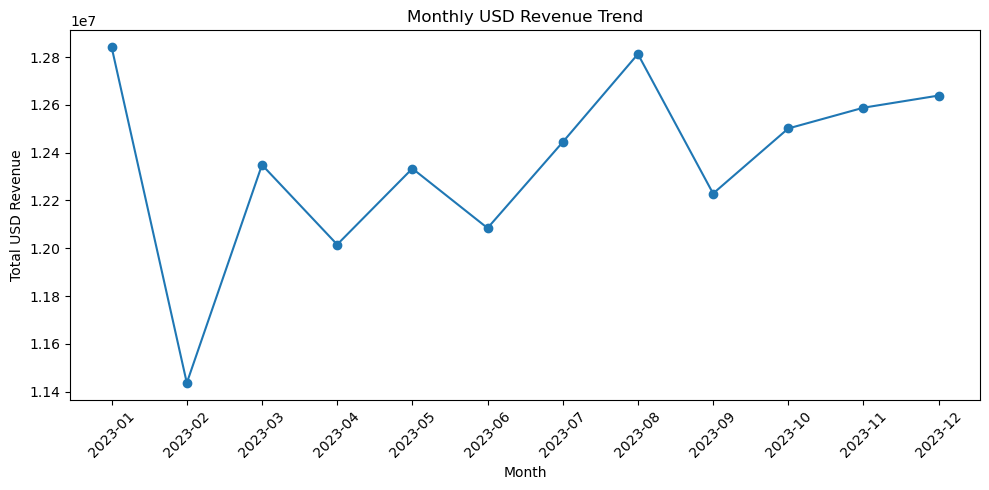

In [37]:
# Monthly USD Revenue Trend

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_revenue['Month'],
    monthly_revenue['USD_Revenue'],
    marker='o'
)

plt.title('Monthly USD Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total USD Revenue')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [38]:
# Top 5 Customers by USD Revenue

top_5_customers = (
    df_final_clean
    .groupby(['User_ID', 'name'])['USD_Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)

top_5_customers

,User_ID,name,USD_Revenue
0,U-06582,User_U-06582,40050.988262
1,U-23313,User_U-23313,39555.806629
2,U-03805,User_U-03805,39529.945085
3,U-20018,User_U-20018,38649.965242
4,U-06489,User_U-06489,38629.142146


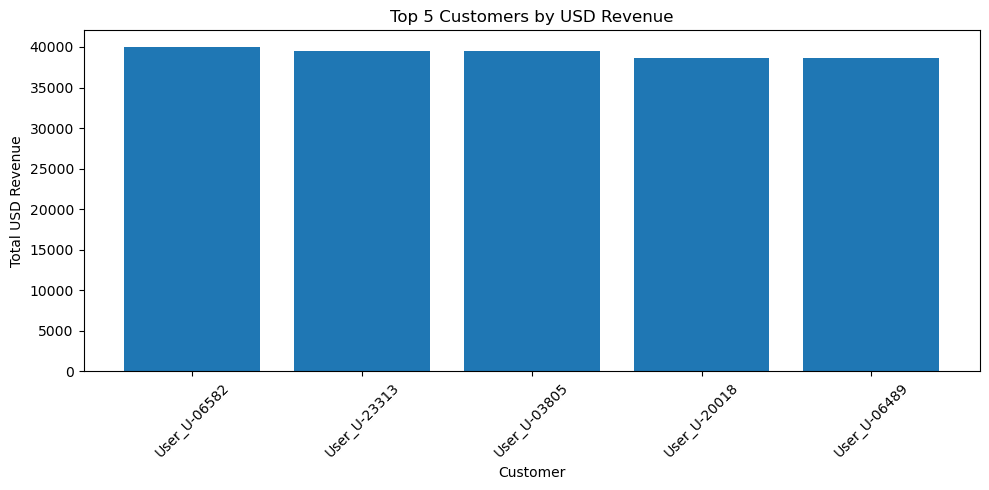

In [39]:
# Top 5 Customers by USD Revenue

plt.figure(figsize=(10, 5))

plt.bar(
    top_5_customers['name'],
    top_5_customers['USD_Revenue']
)

plt.title('Top 5 Customers by USD Revenue')
plt.xlabel('Customer')
plt.ylabel('Total USD Revenue')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()